# Y_tx-conv

taxa de conversão para agricultura e pastagem, proporção 0–1, municipal, anual*

Diagnóstico dos denominadores candidatos. A seção Passos 1 e 2 calcula Y_tx-conv com transições e denominador na mesma máscara.

Fonte: `HIPOTESES TESE - CHAP1.txt`.

- `2_INTI\xdata\chap1\processed\tabular\h2__native_veg__mapbiomas_col10_1__candidato.csv`

**Regras específicas do dicionário**

- Construir: área convertida por destino / área nativa no início do período.
- Este arquivo fornece o denominador candidato (native_veg_ha_lag1), não o numerador.
- Compatibilizar geografia e máscara com as transições; denominador zero implica taxa indefinida.

**Recorte confirmado pelo autor:** 2001–2024; referência territorial de 141 municípios. Os dados espaciais são reextraídos na malha IBGE 2023. Boa Esperança do Norte não é somada integralmente a um único município. Registros e pixels são atribuídos aos territórios anteriores; rendimentos e proporções são recalculados. Essa referência não resolve automaticamente todas as mudanças municipais anteriores a 2023.

## FASE 1: Setup & Load

Execute as células na ordem. As funções abaixo padronizam leitura e gráficos. Os arquivos originais são apenas lidos. Códigos municipais são texto; `ano` identifica o período. O hífen no nome reúne candidatos, não indica subtração.

In [1]:
"""Funções incorporadas nas células dos notebooks pelo gerador."""
from pathlib import Path
import csv
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Aumente para ver mais grupos; as tabelas descritivas sempre incluem todos.
MAX_GRUPOS_GRAFICOS = 6


def encontrar_raiz(inicio=None):
    """Funciona com o kernel aberto na raiz ou na pasta do notebook."""
    inicio = Path(inicio or Path.cwd()).resolve()
    for pasta in [inicio, *inicio.parents]:
        if (pasta / '2_INTI/RESEARCH_PROTOCOL.md').is_file():
            return pasta
    raise FileNotFoundError('Abra o VS Code na pasta tese_eco_usp.')


def ler_csv(caminho, ids_embargo=None):
    # Ler como texto preserva códigos, zeros e símbolos de ausência da fonte.
    bruto_ibama = caminho.name.startswith('termo_')
    opcoes = dict(sep=';' if bruto_ibama else ',', encoding='utf-8-sig',
                  dtype='string', keep_default_na=False)
    if caminho.name == 'termo_embargo_historico.csv':
        # Texto descritivo e geometrias grandes não são necessários nesta AED.
        colunas = ['SEQ_TAD', 'SEQ_HIST_TAD', 'DT_ALTERACAO',
                   'DES_STATUS_FORMULARIO', 'SIT_CANCELADO', 'DAT_EMBARGO',
                   'COD_MUNICIPIO', 'MUNICIPIO', 'UF', 'NUM_LONGITUDE_TAD',
                   'NUM_LATITUDE_TAD', 'QTD_AREA_EMBARGADA', 'TIPO_AREA',
                   'SIT_DESEMBARGO', 'DAT_DESEMBARGO', 'SEQ_AUTO_INFRACAO']
        partes = []
        total = 0
        for parte in pd.read_csv(caminho, usecols=colunas, chunksize=50000, **opcoes):
            total += len(parte)
            # A união permite identificar códigos e UFs discordantes depois.
            mt = parte['UF'].str.strip().eq('MT') | parte['COD_MUNICIPIO'].str.startswith('51')
            partes.append(parte.loc[mt].copy())
        resultado = pd.concat(partes, ignore_index=True)
        print(f'Histórico: {total:,} linhas lidas; {len(resultado):,} candidatas a MT.')
        return resultado
    if caminho.name == 'termo_de_embargo_coordenadas.csv':
        partes = []
        for parte in pd.read_csv(caminho, chunksize=50000, **opcoes):
            if ids_embargo is not None:
                parte = parte.loc[parte['SEQ_TAD'].isin(ids_embargo)]
            partes.append(parte.copy())
        return pd.concat(partes, ignore_index=True)
    return pd.read_csv(caminho, **opcoes)


def limpar_base(original):
    base = original.copy()
    for col in base:
        base[col] = base[col].str.strip().replace('', pd.NA)
    # Só cópias idênticas são retiradas. Eventos sem ID não podem ser deduplicados.
    repetidas = base.duplicated()
    if 'SEQ_AUTO_INFRACAO' in base and 'SEQ_TAD' not in base:
        repetidas &= base['SEQ_AUTO_INFRACAO'].notna()
    if 'SEQ_TAD' in base:
        repetidas &= base['SEQ_TAD'].notna()
    print('Linhas inteiramente repetidas retiradas:', int(repetidas.sum()))
    base = base.loc[~repetidas].copy()
    numeros = {
        'ano', 'mes', 'class_id', 'area_ha', 'area_mapeada_ha',
        'native_veg_ha_it', 'native_veg_share_it', 'native_veg_ha_lag1',
        'native_veg_share_lag1', 'valor_original', 'preco_nominal',
        'ln_price', 'dln_price', 'area_colhida_ha', 'area_plantada_ha',
        'producao_t', 'rendimento_medio_kg_ha', 'yield_calculado_kg_ha',
        'valor_medio', 'n_pixels_validos', 'n_autos_ibama_it',
        'n_autos_ibama_espacial', 'n_valores_ausentes', 'valor_multas_ibama_it',
        'valor_multas_ibama_espacial', 'valor_multa_nominal', 'efetivo_bovino',
        'biome_amazonia_share_i', 'biome_cerrado_share_i', 'biome_pantanal_share_i',
        'soma_fracoes', 'precip_mm', 'fracao_pixels_validos', 'precip_mm_anual',
        'count', 'sum', 'elevation_mean_m', 'elevation_min_m', 'elevation_max_m',
        'n_pixels', 'linha_excel', 'coluna_excel',
    }
    numeros.update(c for c in base if c.startswith(('precip_anomaly_', 'precip_zscore_',
                    'precip_deficit_', 'precip_excess_', 'mean_', 'std_', 'count_')))
    brasileiros = {'QTD_AREA_EMBARGADA', 'NUM_LONGITUDE_TAD', 'NUM_LATITUDE_TAD',
                    'LONGITUDE', 'LATITUDE', 'AREA_POLIGONO'}
    for col in base.columns.intersection(list(numeros | brasileiros)):
        texto = base[col]
        if col in brasileiros:
            # Nestes campos, vírgula é separador decimal; não inventar milhares.
            texto = texto.str.replace(',', '.', regex=False)
        convertido = pd.to_numeric(texto, errors='coerce')
        invalidos = texto.notna() & convertido.isna()
        if invalidos.any():
            print(col, ': valores não numéricos preservados em bases_brutas:',
                  texto.loc[invalidos].value_counts().head().to_dict())
        base[col] = convertido.replace([np.inf, -np.inf], np.nan)
    datas = ['data', 'DAT_HORA_AUTO_INFRACAO', 'DT_FATO_INFRACIONAL',
             'DAT_EMBARGO', 'DT_ALTERACAO', 'DAT_DESEMBARGO']
    for col in base.columns.intersection(datas):
        texto = base[col]
        base[col] = pd.to_datetime(texto, errors='coerce', format='mixed')
        print(col, ': datas inválidas =', int((texto.notna() & base[col].isna()).sum()))
    if 'data' in base:
        base['ano'] = base['data'].dt.year.astype('Int64')
        base['mes'] = base['data'].dt.month.astype('Int64')
    if 'COD_MUNICIPIO' in base and 'codigo_ibge' not in base:
        base['codigo_ibge'] = base['COD_MUNICIPIO'].copy()
    if 'DT_ALTERACAO' in base:
        # Ano de alteração do registro: não é uma contagem de embargos novos.
        base['ano'] = base['DT_ALTERACAO'].dt.year.astype('Int64')
    for col in base.columns.intersection(['codigo_ibge', 'codigo_ibge_espacial']):
        base[col] = base[col].astype('string').str.replace(r'\.0$', '', regex=True)
        base[f'{col}_valido'] = base[col].str.fullmatch(r'\d{7}', na=False)
        print(col, ': códigos ausentes/inválidos =', int((~base[f'{col}_valido']).sum()))
    if {'UF', 'codigo_ibge'}.issubset(base):
        base['flag_uf_codigo_divergente'] = base['UF'].eq('MT') != base['codigo_ibge'].str.startswith('51')
        print('Divergências UF/código para MT:', int(base['flag_uf_codigo_divergente'].sum()))
    for col in base.columns.intersection(['ano', 'mes', 'class_id']):
        fracionario = base[col].notna() & base[col].mod(1).ne(0)
        if fracionario.any():
            raise ValueError(f'{col} tem valores fracionários; confira a fonte.')
        base[col] = base[col].astype('Int64')
    for col in base.columns.intersection(['produto', 'variavel', 'biome', 'nivel_insumo',
                                          'regime', 'unidade', 'TIPO_INFRACAO', 'SIT_CANCELADO']):
        base[col] = base[col].astype('category')
    return base


def aplicar_referencia_141(bases, caminhos, raiz):
    """Usa derivados espaciais recalculados; nunca soma médias municipais."""
    pasta = raiz / '2_INTI/xdata/chap1/processed/territorio_141'
    manifesto_path = pasta / 'manifesto141.json'
    if not manifesto_path.is_file():
        raise FileNotFoundError('Execute reconstruir_territorio141.py antes da AED de 141 municípios.')
    manifesto = json.loads(manifesto_path.read_text(encoding='utf-8'))
    cadastro = pd.DataFrame(json.loads((pasta / 'municipios_referencia.json').read_text(encoding='utf-8')))
    codigos = set(cadastro['codigo_ibge'].astype(str))
    if len(codigos) != 141 or '5101837' in codigos:
        raise ValueError('Cadastro territorial incompatível com a referência de 141 municípios.')
    resultado = []
    for base, relativo in zip(bases, caminhos):
        original = raiz / relativo.replace('\\', '/')
        nome = original.name
        if nome in manifesto['arquivos']:
            registro = manifesto['arquivos'][nome]
            derivado = pasta / nome
            for arquivo, esperado in [(original, registro['origem_sha256']), (derivado, registro['derivado_sha256'])]:
                if hashlib.sha256(arquivo.read_bytes()).hexdigest() != esperado:
                    raise ValueError(f'{arquivo.name} mudou. Reconstrua e valide os derivados territoriais.')
            base = limpar_base(ler_csv(derivado))
            print('Referência IBGE 2023 aplicada por reextração espacial:', nome)
        else:
            base = base.copy()
        if 'codigo_ibge' in base:
            novo = base['codigo_ibge'].eq('5101837').fillna(False)
            if novo.any():
                # PAM só registra produção do novo município em 2025, fora do painel.
                if 'pam_soja_milho' not in nome:
                    raise ValueError('Há observações do novo município sem desagregação territorial validada.')
                medidas = ['area_colhida_ha', 'area_plantada_ha', 'producao_t', 'rendimento_medio_kg_ha']
                no_periodo = novo & base['ano'].le(2024)
                if base.loc[no_periodo, medidas].notna().any().any():
                    raise ValueError('PAM tem medidas novas antes de 2025; revisar território antes de redistribuir.')
                print('PAM: retiradas do recorte de 141 apenas linhas vazias de Boa Esperança até 2024 e registros pós-painel.')
                print('Todas as linhas de origem permanecem em bases_fontes_limpas e bases_brutas.')
                base = base.loc[~novo].copy()
            print('Municípios presentes:', base['codigo_ibge'].nunique(), '/ referência de 141')
            fora = base['codigo_ibge'].notna() & ~base['codigo_ibge'].isin(codigos)
            if fora.any():
                print('Códigos fora do cadastro, preservados para conferência:', sorted(base.loc[fora, 'codigo_ibge'].unique()))
        resultado.append(base)
    return resultado, cadastro


def assert_unique(base, chaves):
    if base[chaves].isna().any().any():
        raise ValueError(f'Chave ausente: {chaves}')
    if base.duplicated(chaves).any():
        raise ValueError(f'Chave repetida: {chaves}. Não agregar conflitos automaticamente.')


def harmonizar_codigos(base, correspondencia, chaves):
    """Esqueleto para mapa 1:1 por ano já validado pelo pesquisador."""
    # Não resolve desmembramentos: áreas e totais exigem pesos territoriais próprios.
    assert_unique(correspondencia, ['codigo_ibge', 'ano'])
    out = base.merge(correspondencia[['codigo_ibge', 'ano', 'codigo_harmonizado']],
                     on=['codigo_ibge', 'ano'], how='left', validate='many_to_one')
    if out['codigo_harmonizado'].isna().any():
        raise ValueError('Falta correspondência territorial; não manter código silenciosamente.')
    out['codigo_ibge_original'] = out['codigo_ibge']
    out['codigo_ibge'] = out.pop('codigo_harmonizado').astype('string')
    assert_unique(out, chaves)
    return out


def recortar(base):
    if 'ano' in base:
        print('Linhas sem ano:', int(base['ano'].isna().sum()))
        return base.loc[base['ano'].between(2001, 2024).fillna(False)].copy()
    print('Fonte sem ano validado: sem replicação artificial em 2001–2024.')
    return base.copy()


def diagnosticar(base, valores, chaves):
    if chaves:
        conflitos = base.loc[base.duplicated(chaves, keep=False)]
        print('Linhas com chave repetida:', len(conflitos))
        if len(conflitos):
            display(conflitos.head(10))
    linhas = []
    for col in valores:
        s = base[col]
        linhas.append({'medida': col, 'linhas': len(s), 'ausente_na_linha': int(s.isna().sum()),
                       'zero_registrado': int(s.eq(0).sum()), 'nao_zero': int((s.notna() & s.ne(0)).sum())})
    display(pd.DataFrame(linhas))
    print('Zero registrado não prova zero verdadeiro: conferir a regra da fonte.')
    print('Ausência de cultivo e medida não construída exigem informação própria.')


def lacunas_painel(base, grupos):
    # O universo abaixo contém só municípios presentes na fonte, não todos os de MT.
    if {'data', 'variavel'}.issubset(base):
        grade = pd.DataFrame({'data': pd.date_range('2001-01-01', '2024-12-01', freq='MS')})
        grade = grade.merge(base[['variavel']].dropna().drop_duplicates(), how='cross')
        presentes = base[['data', 'variavel']].drop_duplicates().assign(registro_presente=True)
        cobertura = grade.merge(presentes, on=['data', 'variavel'], how='left', validate='one_to_one')
        faltam = cobertura['registro_presente'].isna()
        print('Meses sem registro de preço em 2001–2024:', int(faltam.sum()))
        display(cobertura.loc[faltam].head(10))
        return
    if not {'codigo_ibge', 'ano'}.issubset(base):
        return
    unidades = ['codigo_ibge'] + grupos
    existentes = base[unidades].dropna().drop_duplicates()
    anos = pd.DataFrame({'ano': pd.Series(range(2001, 2025), dtype='Int64')})
    grade = existentes.merge(anos, how='cross')
    if 'mes' in base:
        grade = grade.merge(pd.DataFrame({'mes': range(1, 13)}), how='cross')
    chave = list(grade.columns)
    presentes = base[chave].drop_duplicates().assign(registro_presente=True)
    cobertura = grade.merge(presentes, on=chave, how='left', validate='one_to_one')
    faltam = cobertura['registro_presente'].isna()
    print('Combinações sem linha no universo observado:', int(faltam.sum()))
    print('Grade diagnóstica; não preenche os dados nem comprova existência histórica do município.')
    display(cobertura.loc[faltam].head(10))


def rotular_grupos(base, grupos):
    out = base.copy()
    if grupos:
        out['_grupo'] = out[grupos].astype('string').fillna('(ausente)').agg(' | '.join, axis=1)
    else:
        out['_grupo'] = 'Todas as observações'
    return out


def grupos_para_grafico(base):
    grupos = sorted(base['_grupo'].dropna().unique())
    if len(grupos) > MAX_GRUPOS_GRAFICOS:
        print(f'Gráficos limitados aos primeiros {MAX_GRUPOS_GRAFICOS} de {len(grupos)} grupos, em ordem.')
        print('Aumente MAX_GRUPOS_GRAFICOS na fase 1 para mostrar todos.')
    return grupos[:MAX_GRUPOS_GRAFICOS]


def graficos_univariados(base, valores, grupos, unidades):
    plot = rotular_grupos(base, grupos)
    labels = grupos_para_grafico(plot)
    # Painéis separados evitam misturar culturas, classes e cenários.
    for col in valores:
        for label in labels:
            sub = plot.loc[plot['_grupo'].eq(label)]
            s = sub[col].dropna().astype(float)
            if s.empty:
                print('Sem valores para plotar:', col, label)
                continue
            fig, axes = plt.subplots(1, 2, figsize=(11, 3))
            sns.histplot(x=s, bins=30, ax=axes[0])
            sns.boxplot(x=s, ax=axes[1])
            for ax in axes:
                ax.set_xlabel(f'{col} ({unidades.get(col, "ver dicionário")})')
            fig.suptitle(f'{col} — {label}')
            fig.tight_layout()
            plt.show()
            plt.close(fig)
    print('Extremos são sinalizados pelo boxplot; nenhum foi removido ou winsorizado.')


def graficos_tempo(base, valores, grupos, unidades):
    if 'ano' not in base:
        print('Sem dimensão temporal validada nesta fonte.')
        return
    plot = rotular_grupos(base, grupos)
    selecionados = grupos_para_grafico(plot)
    plot = plot.loc[plot['_grupo'].isin(selecionados)]
    for col in valores:
        fig, ax = plt.subplots(figsize=(11, 4))
        for label, sub in plot.groupby('_grupo', observed=True):
            serie = sub.groupby('ano', observed=True)[col].median().reindex(range(2001, 2025))
            ax.plot(serie.index, serie.to_numpy(dtype=float, na_value=np.nan), label=label)
        ax.set(xlabel='Ano', ylabel=f'Mediana de {col} ({unidades.get(col, "ver dicionário")})',
               title='Evolução descritiva: observações disponíveis em cada ano', xlim=(2001, 2024))
        ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1, 1))
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    print('Medianas descritivas; composição da amostra pode variar. Não são agregações finais.')
    cobertura = base.groupby('ano', observed=True).size().rename('n_linhas').reindex(range(2001, 2025))
    display(cobertura.to_frame())


def graficos_bivariados(base, valores, grupos, unidades):
    if not valores or base.empty:
        print('Sem medida pronta para comparação bivariada.')
        return
    plot = rotular_grupos(base, grupos)
    selecionados = grupos_para_grafico(plot)
    plot = plot.loc[plot['_grupo'].isin(selecionados)]
    if {'codigo_ibge', 'ano'}.issubset(base):
        # Até 20 códigos em ordem: exemplo legível, sem pretensão de representatividade.
        for label, sub in plot.groupby('_grupo', observed=True):
            codigos = sorted(sub['codigo_ibge'].dropna().unique())[:20]
            for col in valores:
                matriz = sub.loc[sub['codigo_ibge'].isin(codigos)].pivot_table(
                    index='codigo_ibge', columns='ano', values=col, aggfunc='median', observed=True)
                matriz = matriz.reindex(index=codigos, columns=range(2001, 2025))
                if matriz.empty or not matriz.notna().any().any():
                    continue
                fig, ax = plt.subplots(figsize=(12, 6))
                sns.heatmap(matriz.astype(float), mask=matriz.isna(), cmap='viridis', ax=ax,
                            cbar_kws={'label': unidades.get(col, col)})
                ax.set_title(f'{col} por município e ano — {label}\nMediana; branco = ausente')
                fig.tight_layout()
                plt.show()
                plt.close(fig)
    elif 'codigo_ibge' in base:
        for label, sub in plot.groupby('_grupo', observed=True):
            for col in valores:
                pequeno = sub.sort_values('codigo_ibge').head(20)
                fig, ax = plt.subplots(figsize=(10, 4))
                sns.barplot(data=pequeno, x='codigo_ibge', y=col, errorbar=None, ax=ax)
                ax.tick_params(axis='x', rotation=90)
                ax.set_title(f'{col} — {label}; primeiros 20 códigos (estático)')
                ax.set_ylabel(unidades.get(col, col))
                fig.tight_layout()
                plt.show()
                plt.close(fig)
    elif {'data', 'variavel', 'preco_nominal'}.issubset(base):
        assert_unique(base, ['data', 'variavel'])
        largo = base.pivot(index='data', columns='variavel', values='preco_nominal')
        if largo.shape[1] == 2:
            fig, ax = plt.subplots(figsize=(5, 4))
            sns.scatterplot(data=largo, x=largo.columns[0], y=largo.columns[1], ax=ax)
            ax.set_title('Preços mensais: associação descritiva, USD/t')
            plt.show()
            plt.close(fig)
        else:
            sazonal = base.assign(mes=base['data'].dt.month)
            fig, ax = plt.subplots(figsize=(8, 4))
            sns.boxplot(data=sazonal, x='mes', y='preco_nominal', ax=ax)
            ax.set_title('Preço mensal por mês do calendário; USD/kg')
            plt.show()
            plt.close(fig)
    elif 'aba' in base:
        fig, ax = plt.subplots(figsize=(10, 5))
        sns.barplot(data=base.head(20), y='aba', x=valores[0], errorbar=None, ax=ax)
        ax.set_title('Cobertura de até 20 abas; ainda não é uma comparação de custos')
        fig.tight_layout()
        plt.show()
        plt.close(fig)


In [2]:
RAIZ = encontrar_raiz()
CAMINHOS = ['2_INTI\\xdata\\chap1\\processed\\tabular\\h2__native_veg__mapbiomas_col10_1__candidato.csv']
NOME = 'Y_tx-conv'
CHAVE = ['codigo_ibge', 'ano']
GRUPOS = []
VALORES = ['native_veg_ha_lag1', 'native_veg_share_lag1']
UNIDADES = {'native_veg_ha_lag1': 'ha no início do período', 'native_veg_share_lag1': 'proporção 0–1'}
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 20)
# Todas as fontes do bloco são lidas, na ordem em que aparecem no TXT.
bases_brutas = []
for relativo in CAMINHOS:
    caminho = RAIZ / relativo.replace('\\', '/')
    ids = None
    if caminho.name == 'termo_de_embargo_coordenadas.csv' and bases_brutas:
        ids = set(bases_brutas[0]['SEQ_TAD'].dropna()) - {''}
    base = ler_csv(caminho, ids_embargo=ids)
    bases_brutas.append(base)
    print(caminho.name, '— shape:', base.shape)
    display(base.head())
    base.info()
display(pd.DataFrame(UNIDADES.items(), columns=['coluna analisada', 'significado / unidade']))


h2__native_veg__mapbiomas_col10_1__candidato.csv — shape: (5640, 9)


,codigo_ibge,municipio,ano,area_mapeada_ha,native_veg_ha_it,uf,native_veg_share_it,native_veg_ha_lag1,native_veg_share_lag1
0,5100102,Acorizal,1985,85076.37842079374,74678.20908532004,MT,0.8777784206558061,,
1,5100102,Acorizal,1986,85076.37842079786,74110.97659082332,MT,0.8711110882536823,74678.20908532004,0.8777784206558061
2,5100102,Acorizal,1987,85076.3784207981,73461.79038824797,MT,0.8634804601683566,74110.97659082332,0.8711110882536823
3,5100102,Acorizal,1988,85076.3784207973,73202.5578272181,MT,0.8604334033255395,73461.79038824797,0.8634804601683566
4,5100102,Acorizal,1989,85076.37842079422,72397.49208884223,MT,0.8509705447352113,73202.5578272181,0.8604334033255395


<class 'pandas.DataFrame'>
RangeIndex: 5640 entries, 0 to 5639
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   codigo_ibge            5640 non-null   string
 1   municipio              5640 non-null   string
 2   ano                    5640 non-null   string
 3   area_mapeada_ha        5640 non-null   string
 4   native_veg_ha_it       5640 non-null   string
 5   uf                     5640 non-null   string
 6   native_veg_share_it    5640 non-null   string
 7   native_veg_ha_lag1     5640 non-null   string
 8   native_veg_share_lag1  5640 non-null   string
dtypes: string(9)
memory usage: 396.7 KB


,coluna analisada,significado / unidade
0,native_veg_ha_lag1,ha no início do período
1,native_veg_share_lag1,proporção 0–1


## FASE 2: Data Cleaning & Wrangling

Limpeza conserva o histórico completo em `df` e as fontes lidas em `bases_brutas`. `painel` contém 2001–2024 quando existe ano validado. Só linhas inteiramente repetidas são retiradas; conflitos de chave e valores ausentes ficam visíveis.

In [3]:
# Construir: área convertida por destino / área nativa no início do período.
# Este arquivo fornece o denominador candidato (native_veg_ha_lag1), não o numerador.
# Compatibilizar geografia e máscara com as transições; denominador zero implica taxa indefinida.
bases_fontes_limpas = [limpar_base(base) for base in bases_brutas]
# Os CSVs indicados no TXT foram lidos acima; a transformação territorial é explícita.
bases, MUNICIPIOS_141 = aplicar_referencia_141(bases_fontes_limpas, CAMINHOS, RAIZ)
df = bases[0].copy()

painel = recortar(df)
analise = painel.copy()
print('Diagnóstico da chave na fonte selecionada:')
diagnosticar(df, [v for v in VALORES if v in df], CHAVE)


Linhas inteiramente repetidas retiradas: 0
codigo_ibge : códigos ausentes/inválidos = 0
Municípios presentes: 141 / referência de 141
Linhas sem ano: 0
Diagnóstico da chave na fonte selecionada:
Linhas com chave repetida: 0


,medida,linhas,ausente_na_linha,zero_registrado,nao_zero
0,native_veg_ha_lag1,5640,141,0,5499
1,native_veg_share_lag1,5640,141,0,5499


Zero registrado não prova zero verdadeiro: conferir a regra da fonte.
Ausência de cultivo e medida não construída exigem informação própria.


## FASE 3: Estatística Descritiva Básica

`ausente_na_linha` significa célula sem medida; uma combinação sem linha é outra situação. `zero_registrado` é zero presente no arquivo, ainda sujeito à validação da fonte. Ausência de cultivo não pode ser deduzida apenas de um rendimento vazio. Uma medida ainda não construída permanece explicitamente pendente.

In [4]:
diagnosticar(analise, VALORES, [])
display(analise[VALORES].describe().T)
if GRUPOS:
    display(analise.groupby(GRUPOS, observed=True)[VALORES].describe())
lacunas_painel(df, [c for c in GRUPOS if c in df and c != 'concordancia'])


,medida,linhas,ausente_na_linha,zero_registrado,nao_zero
0,native_veg_ha_lag1,3384,0,0,3384
1,native_veg_share_lag1,3384,0,0,3384


Zero registrado não prova zero verdadeiro: conferir a regra da fonte.
Ausência de cultivo e medida não construída exigem informação própria.


,count,mean,std,min,25%,50%,75%,max
native_veg_ha_lag1,3384.0,416823.734975,495643.598813,6484.720236,100898.708805,250878.518833,438465.890436,2737545.069287
native_veg_share_lag1,3384.0,0.544844,0.196865,0.072744,0.413275,0.553972,0.681241,0.979049


Combinações sem linha no universo observado: 0
Grade diagnóstica; não preenche os dados nem comprova existência histórica do município.


,codigo_ibge,ano,registro_presente


## FASE 4: Análise Univariada

Histogramas mostram a distribuição; boxplots destacam extremos sem removê-los. Produtos, classes e cenários aparecem separados. A evolução usa medianas das observações de cada ano e mantém lacunas; ela não substitui a agregação final da fase 6. Fontes estáticas não recebem anos artificiais.

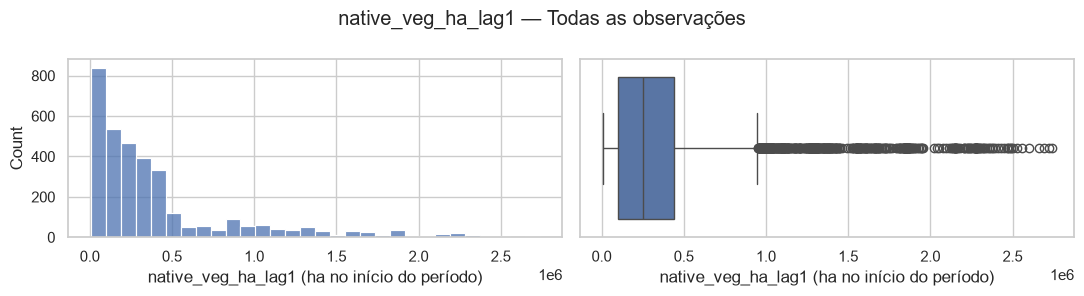

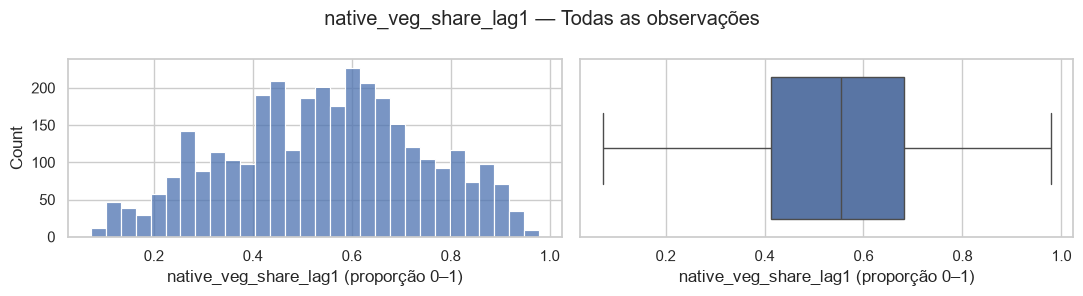

Extremos são sinalizados pelo boxplot; nenhum foi removido ou winsorizado.


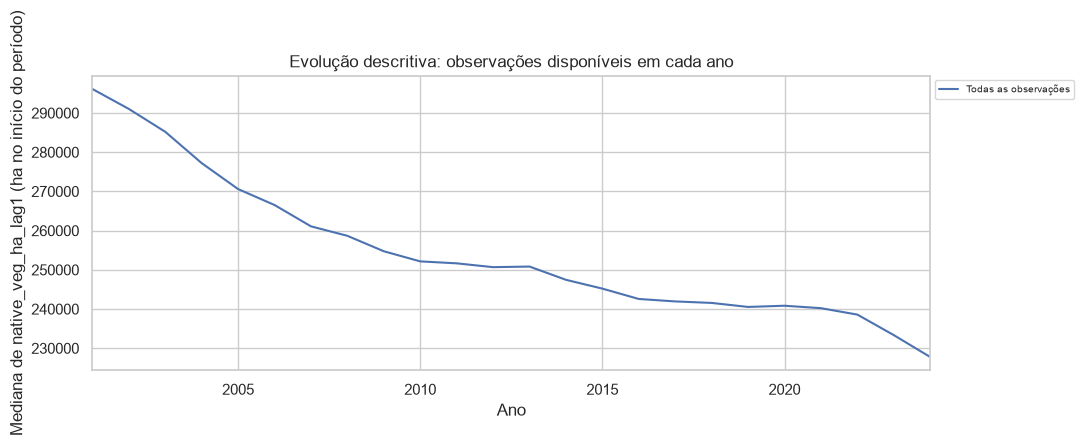

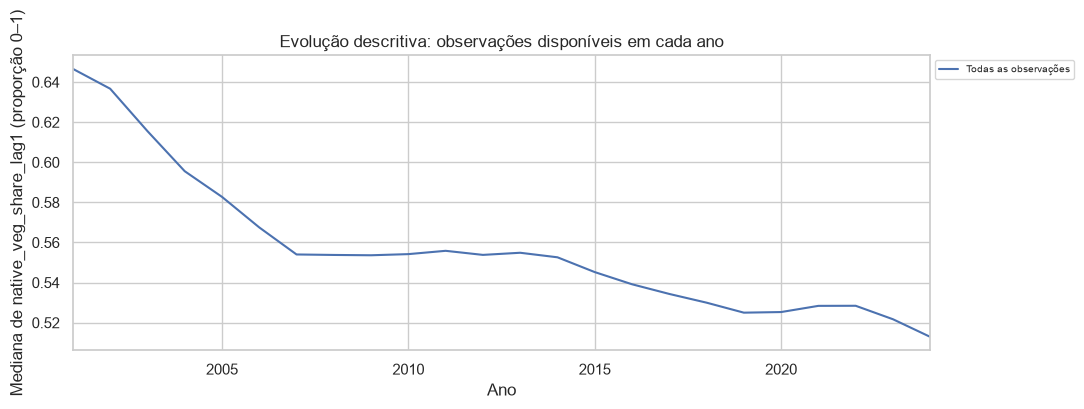

Medianas descritivas; composição da amostra pode variar. Não são agregações finais.


,n_linhas
ano,
2001,141
2002,141
2003,141
2004,141
2005,141
...,...
2020,141
2021,141
2022,141


In [5]:
graficos_univariados(analise, VALORES, GRUPOS, UNIDADES)
graficos_tempo(analise, VALORES, GRUPOS, UNIDADES)


## FASE 5: Análise Bivariada

Cruze município e ano por medida e grupo disponível. Os mapas de calor mostram até 20 códigos em ordem, apenas para legibilidade; branco significa ausência. Preços globais são comparados entre produtos ou meses. Em dados estáticos, compare municípios; em CONAB, compare cobertura de abas. Essas relações são descritivas, sem interpretação causal.

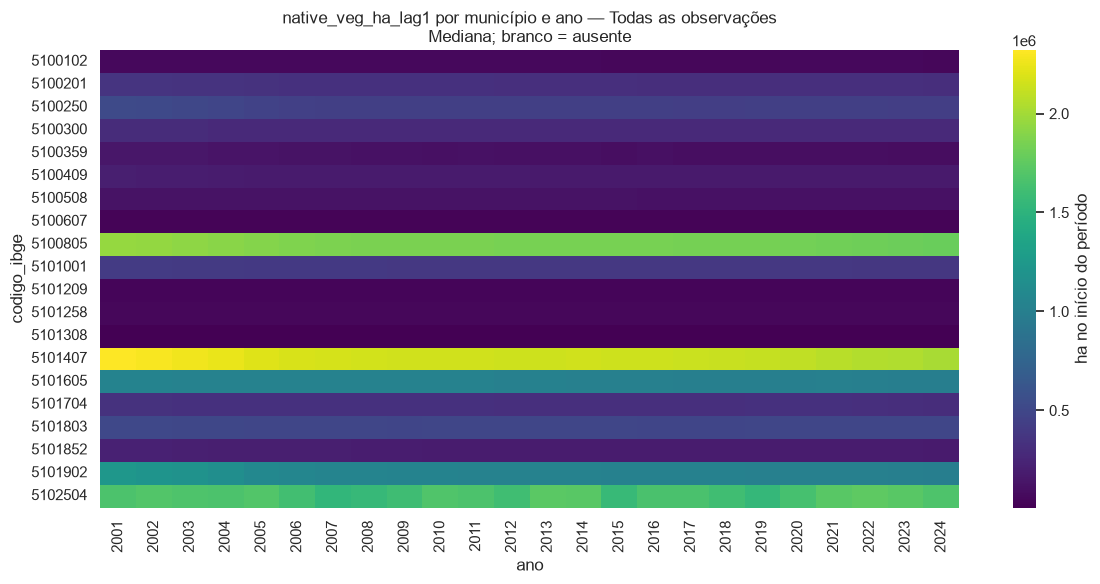

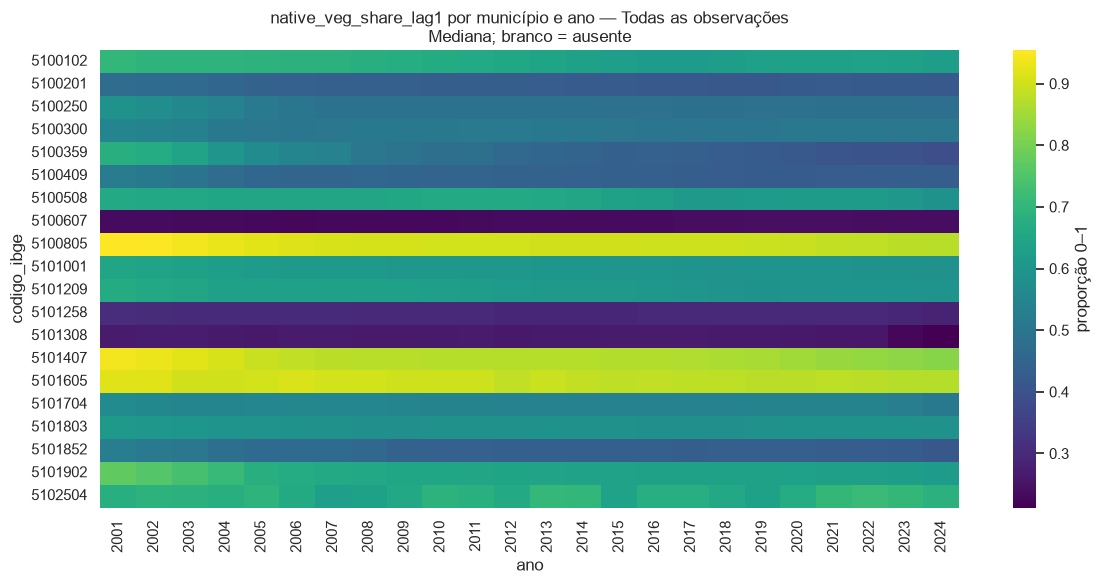

In [6]:
graficos_bivariados(analise, VALORES, GRUPOS, UNIDADES)


## FASE 6: Feature Engineering (Tratamentos Finais)

A primeira parte preserva as funções e condições da AED inicial. `None` sinaliza uma condição ainda não satisfeita; não é zero. Ao final desta fase, a seção **Passos 1 e 2 — Construção executada das variáveis** aplica o plano autorizado, documenta os parâmetros e exporta os derivados disponíveis. Ela mantém explícitas as medidas adiadas e não define uma especificação econométrica.

In [7]:
# Construir: área convertida por destino / área nativa no início do período.
# Este arquivo fornece o denominador candidato (native_veg_ha_lag1), não o numerador.
# Compatibilizar geografia e máscara com as transições; denominador zero implica taxa indefinida.
# `features` guarda uma tabela candidata em memória; os CSVs não são alterados.
features = None

def recorte_2001_2024(base):
    if "ano" not in base.columns:
        return base.copy()
    return base.loc[pd.to_numeric(base["ano"], errors="coerce").between(2001, 2024)].copy()

def abrir_colunas(base, indice, categoria, valor):
    # pivot exige uma medida por chave; não calcula médias para esconder duplicatas.
    chave = indice + [categoria]
    if base[chave].isna().any().any() or base.duplicated(chave).any():
        print("Pivô pendente: resolver chaves ausentes ou duplicadas:", chave)
        return None
    assert_unique(base, chave)
    return base.pivot(index=indice, columns=categoria, values=valor).reset_index()

def deflacionar(base, indice, coluna_valor, chaves, indice_base):
    # indice deve conter `indice_precos`, positivo, na frequência e moeda corretas.
    # indice_base é o nível do índice na data-base escolhida (não presumir 100).
    if indice_base <= 0:
        raise ValueError("O índice da data-base deve ser positivo.")
    assert_unique(indice, chaves)
    out = base.merge(indice[chaves + ["indice_precos"]], on=chaves,
                     how="left", validate="many_to_one")
    out[coluna_valor + "_real"] = (
        out[coluna_valor] * indice_base / out["indice_precos"].where(out["indice_precos"] > 0)
    )
    return out

def construir_taxas(conversao_municipal, denominador, compatibilidade_validada=False):
    # Numerador: uma linha por município, ano e destino; area_conv_ha em hectares.
    # Denominador: vegetação no início do período, já presente na fonte candidata.
    if not compatibilidade_validada:
        raise ValueError("Validar geografia, datas e máscara das duas medidas.")
    chaves = ["codigo_ibge", "ano"]
    assert_unique(conversao_municipal, chaves + ["destino"])
    assert_unique(denominador, chaves)
    if conversao_municipal[chaves + ["destino"]].isna().any().any():
        raise ValueError("Numerador contém chave ausente.")
    if not set(conversao_municipal["destino"].dropna()) <= {"agricultura", "pastagem"}:
        raise ValueError("Separar os destinos agricultura e pastagem.")
    out = conversao_municipal.merge(
        denominador[chaves + ["native_veg_ha_lag1"]], on=chaves,
        how="left", validate="many_to_one", indicator=True,
    )
    den = out["native_veg_ha_lag1"]
    num = out["area_conv_ha"]
    out["taxa_conv"] = num / den.where(den > 0)
    out["flag_taxa_fora_0_1"] = out["taxa_conv"].notna() & ~out["taxa_conv"].between(0, 1)
    # Não limitar em 1: inconsistências precisam aparecer na conferência.
    out["flag_denominador_nulo"] = den.eq(0)
    out["flag_denominador_ausente"] = den.isna()
    return out

CONVERSAO_MUNICIPAL_VALIDADA = None
COMPATIBILIDADE_VALIDADA = False
if CONVERSAO_MUNICIPAL_VALIDADA is not None and COMPATIBILIDADE_VALIDADA:
    taxas = construir_taxas(CONVERSAO_MUNICIPAL_VALIDADA, df, True)
    display(taxas[["_merge", "flag_denominador_nulo", "flag_taxa_fora_0_1"]].value_counts())
    features = abrir_colunas(recorte_2001_2024(taxas), ["codigo_ibge", "ano"], "destino", "taxa_conv")
    display(features.head() if features is not None else "Pivô pendente.")
else:
    print("Esqueleto inicial: este CSV contém o denominador candidato. A taxa executada está na seção Passos 1 e 2 abaixo.")
    print("Denominador zero mantém a taxa ausente; não vira taxa zero.")


Esqueleto inicial: este CSV contém o denominador candidato. A taxa executada está na seção Passos 1 e 2 abaixo.
Denominador zero mantém a taxa ausente; não vira taxa zero.


In [8]:
# A referência espacial de 141 municípios já foi aplicada na fase 2.
# O mapa abaixo serve para OUTRAS mudanças históricas de códigos, depois de validadas.
# Boa Esperança tem mais de uma origem: esse mapa 1:1 não serve para desfazer sua criação.
CORRESPONDENCIA = None
base_harmonizada = df.copy()
if CORRESPONDENCIA is not None:
    if 'ano' not in df:
        raise ValueError('Fonte estática exige correspondência da malha de referência.')
    base_harmonizada = harmonizar_codigos(df, CORRESPONDENCIA, CHAVE)
else:
    print('Referência territorial: 141 municípios, malha IBGE 2023. Outras mudanças históricas ainda exigem validação.')
    print('Não foi produzido painel econométrico final nem escolhida especificação.')
# Desmembramentos não se resolvem renomeando códigos. Não fazer junção muitos-para-muitos.
# Ao combinar fontes, usar validate e indicator e revisar municípios sem correspondência.


Referência territorial: 141 municípios, malha IBGE 2023. Outras mudanças históricas ainda exigem validação.
Não foi produzido painel econométrico final nem escolhida especificação.


**Pendências comuns extraídas do TXT**

- Harmonizar limites e códigos municipais; preservar dados anteriores a 2001 necessários a denominadores e exposições.
- Manter uma linha por município–ano e colunas próprias para produtos, destinos e alternativas; evitar multiplicação nas junções.
- Distinguir zero, ausência de registro, ausência de cultivo e medida ainda não construída.
- Biomas, capacidade estática e relevo podem informar heterogeneidade; seus níveis são absorvidos por efeitos fixos municipais.
- Preços comuns aos municípios são absorvidos por efeitos fixos de ano; examinar sua interação com exposição local.
- Crédito, CAR, preços locais, temperaturas e histórico de municípios prioritários ainda não estão disponíveis como painéis validados.
- Os candidatos acima não implicam aprovação de controles, índice de retorno ou interpretação causal; decidir após tratamento e descritiva.

In [9]:
# PENDÊNCIA: Harmonizar limites e códigos municipais; preservar dados anteriores a 2001 necessários a denominadores e exposições.
# PENDÊNCIA: Manter uma linha por município–ano e colunas próprias para produtos, destinos e alternativas; evitar multiplicação nas junções.
# PENDÊNCIA: Distinguir zero, ausência de registro, ausência de cultivo e medida ainda não construída.
# PENDÊNCIA: Biomas, capacidade estática e relevo podem informar heterogeneidade; seus níveis são absorvidos por efeitos fixos municipais.
# PENDÊNCIA: Preços comuns aos municípios são absorvidos por efeitos fixos de ano; examinar sua interação com exposição local.
# PENDÊNCIA: Crédito, CAR, preços locais, temperaturas e histórico de municípios prioritários ainda não estão disponíveis como painéis validados.
# PENDÊNCIA: Os candidatos acima não implicam aprovação de controles, índice de retorno ou interpretação causal; decidir após tratamento e descritiva.


### Passos 1 e 2 — Construção executada das variáveis

**Taxas de conversão por destino.** Dividimos cada conversão bruta pela vegetação nativa no início do mesmo intervalo. O numerador e o denominador vêm dos mesmos pixels válidos nos dois mapas. Para 2001, usamos o mapa inicial de 2000. A máscara e o denominador acompanham cada município–ano.

**Fórmula/regra:** `taxa_destino = conversao_destino_ha / nativa_inicial_ha; taxa_pct = 100 × taxa_destino`.

**Interpretação e limite:** Denominador zero torna a taxa indefinida. Taxas inconsistentes não são cortadas em 1. A taxa mede a fração convertida do estoque disponível, não o efeito acumulado sobre toda a vegetação histórica. Cobertura incompleta mantém área convertida e taxa ausentes, sem extrapolar os pixels observados.

Os parâmetros e funções ficam em `harmonizacao.py` e nos módulos `harmonizacao_*`. A execução abaixo aplica as regras, mostra a cobertura e salva os derivados em `2_INTI/xdata/chap1/processed/harmonizacao/`, sem alterar as fontes. As tabelas preservam ausências e motivos; não selecionam uma especificação econométrica.

In [10]:
# Taxas de conversão por destino.
# Regra: taxa_destino = conversao_destino_ha / nativa_inicial_ha; taxa_pct = 100 × taxa_destino
# As seis fases anteriores inspecionam as fontes; esta seção constrói as saídas.
import sys
PASTA_CODIGO = RAIZ / "2_INTI/chapters/chap1/stats/AED/pt"
if str(PASTA_CODIGO) not in sys.path:
    sys.path.insert(0, str(PASTA_CODIGO))
from harmonizacao import construir_variavel
from harmonizacao_comum import exportar_resultado, resumo_cobertura

# bases contém as cópias limpas, já na referência territorial de 141 municípios.
resultado_construcao = construir_variavel(NOME, RAIZ, bases=bases)
tabelas_derivadas = resultado_construcao["tabelas"]
features_construidas = tabelas_derivadas.get(resultado_construcao["principal"])
print("Situação:", resultado_construcao["status"])
display(pd.DataFrame(resultado_construcao["dicionario"]))
display(pd.Series(resultado_construcao["parametros"], name="regra aplicada").to_frame())
for pendencia in resultado_construcao["pendencias"]:
    print("Limitação:", pendencia)


Situação: construida_com_ressalvas


,tabela,coluna,unidade,regra_da_construcao,processo,limite_interpretacao
0,conversao,codigo_ibge,identificador municipal,taxa_destino = conversao_destino_ha / nativa_i...,Dividimos cada conversão bruta pela vegetação ...,Denominador zero torna a taxa indefinida. Taxa...
1,conversao,ano,ano civil,taxa_destino = conversao_destino_ha / nativa_i...,Dividimos cada conversão bruta pela vegetação ...,Denominador zero torna a taxa indefinida. Taxa...
2,conversao,colecao,"metadado, categoria ou unidade indicada na fonte",taxa_destino = conversao_destino_ha / nativa_i...,Dividimos cada conversão bruta pela vegetação ...,Denominador zero torna a taxa indefinida. Taxa...
3,conversao,malha,"metadado, categoria ou unidade indicada na fonte",taxa_destino = conversao_destino_ha / nativa_i...,Dividimos cada conversão bruta pela vegetação ...,Denominador zero torna a taxa indefinida. Taxa...
4,conversao,mascara_id,"metadado, categoria ou unidade indicada na fonte",taxa_destino = conversao_destino_ha / nativa_i...,Dividimos cada conversão bruta pela vegetação ...,Denominador zero torna a taxa indefinida. Taxa...
...,...,...,...,...,...,...
38,cobertura_transicoes,area_valida_par_ha,ha,taxa_destino = conversao_destino_ha / nativa_i...,Dividimos cada conversão bruta pela vegetação ...,Denominador zero torna a taxa indefinida. Taxa...
39,cobertura_transicoes,area_nao_valida_par_ha,ha,taxa_destino = conversao_destino_ha / nativa_i...,Dividimos cada conversão bruta pela vegetação ...,Denominador zero torna a taxa indefinida. Taxa...
40,cobertura_transicoes,nativa_inicial_ha,ha,taxa_destino = conversao_destino_ha / nativa_i...,Dividimos cada conversão bruta pela vegetação ...,Denominador zero torna a taxa indefinida. Taxa...
41,cobertura_transicoes,cobertura_completa,"metadado, categoria ou unidade indicada na fonte",taxa_destino = conversao_destino_ha / nativa_i...,Dividimos cada conversão bruta pela vegetação ...,Denominador zero torna a taxa indefinida. Taxa...


,regra aplicada
periodo_painel,"[2001, 2024]"
territorio,IBGE_2023_141
janela_precos,ano civil anterior (t-1)
janela_pam,"[1991, 2000]"
minimo_anos_pam,7
referencia_chuva_principal,"[1981, 2000]"
referencias_chuva_alternativas,"[[1981, 2010], [1991, 2020]]"
interpretacao,variaveis candidatas; nao implica identificaca...


In [11]:
# Conferimos linhas e ausências antes de salvar. NA não vira zero.
for nome_tabela, tabela in tabelas_derivadas.items():
    print(nome_tabela, "— linhas:", len(tabela), "colunas:", len(tabela.columns))
    display(tabela.head(8))
display(resumo_cobertura(tabelas_derivadas))

# Cada notebook usa uma pasta própria; os CSVs de origem são somente leitura.
PASTA_DERIVADOS = exportar_resultado(resultado_construcao, RAIZ)
print("Derivados e manifesto salvos em:", PASTA_DERIVADOS)


conversao — linhas: 6768 colunas: 16


,codigo_ibge,ano,colecao,malha,mascara_id,area_total_ha,area_valida_par_ha,area_nao_valida_par_ha,nativa_inicial_ha,cobertura_completa,fracao_area_valida_par,conversao_ha,destino,flag_denominador_zero,flag_denominador_ausente,taxa_conversao
0,5100102,2001,10.1,IBGE_MT_2023_141,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87...,85075.640222,85075.640222,0.0,59486.295731,True,1.0,5.093917,agricultura,False,False,0.000086
1,5100102,2002,10.1,IBGE_MT_2023_141,5807cd2f641779260fa4559cbed36ba1758c805727c9ac...,85075.640222,85075.640222,0.0,58878.434055,True,1.0,1.468305,agricultura,False,False,0.000025
2,5100102,2003,10.1,IBGE_MT_2023_141,87e1efe7cc9af76935236018b19355ab089f5ed333ff2c...,85075.640222,85075.640222,0.0,58805.484389,True,1.0,0.172670,agricultura,False,False,0.000003
3,5100102,2004,10.1,IBGE_MT_2023_141,cb73fabdf74ffdec0a72c86f9512fbb2b3ec6eebb880fc...,85075.640222,85075.640222,0.0,58759.069254,True,1.0,0.000000,agricultura,False,False,0.000000
4,5100102,2005,10.1,IBGE_MT_2023_141,9b9c3f1ac4a2aaa976d1f8022532f78a75bd38db951809...,85075.640222,85075.640222,0.0,58501.389359,True,1.0,1.208967,agricultura,False,False,0.000021
5,5100102,2006,10.1,IBGE_MT_2023_141,1b7652b65e3a6cd24e1f03d1eeb558eb64bbc7a1243b1e...,85075.640222,85075.640222,0.0,58329.659620,True,1.0,14.766857,agricultura,False,False,0.000253
6,5100102,2007,10.1,IBGE_MT_2023_141,31585c7ea4b38c9c66725e765f1eb861c5ae93a1425321...,85075.640222,85075.640222,0.0,58306.698542,True,1.0,10.797212,agricultura,False,False,0.000185
7,5100102,2008,10.1,IBGE_MT_2023_141,7b4a018d7aa1532fba7d57f873c1b0b3853cafbc7d2ab0...,85075.640222,85075.640222,0.0,57879.455839,True,1.0,1.122700,agricultura,False,False,0.000019


taxas — linhas: 6768 colunas: 16


,codigo_ibge,ano,colecao,malha,mascara_id,area_total_ha,area_valida_par_ha,area_nao_valida_par_ha,nativa_inicial_ha,cobertura_completa,fracao_area_valida_par,conversao_ha,destino,flag_denominador_zero,flag_denominador_ausente,taxa_conversao
0,5100102,2001,10.1,IBGE_MT_2023_141,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87...,85075.640222,85075.640222,0.0,59486.295731,True,1.0,5.093917,agricultura,False,False,0.000086
1,5100102,2002,10.1,IBGE_MT_2023_141,5807cd2f641779260fa4559cbed36ba1758c805727c9ac...,85075.640222,85075.640222,0.0,58878.434055,True,1.0,1.468305,agricultura,False,False,0.000025
2,5100102,2003,10.1,IBGE_MT_2023_141,87e1efe7cc9af76935236018b19355ab089f5ed333ff2c...,85075.640222,85075.640222,0.0,58805.484389,True,1.0,0.172670,agricultura,False,False,0.000003
3,5100102,2004,10.1,IBGE_MT_2023_141,cb73fabdf74ffdec0a72c86f9512fbb2b3ec6eebb880fc...,85075.640222,85075.640222,0.0,58759.069254,True,1.0,0.000000,agricultura,False,False,0.000000
4,5100102,2005,10.1,IBGE_MT_2023_141,9b9c3f1ac4a2aaa976d1f8022532f78a75bd38db951809...,85075.640222,85075.640222,0.0,58501.389359,True,1.0,1.208967,agricultura,False,False,0.000021
5,5100102,2006,10.1,IBGE_MT_2023_141,1b7652b65e3a6cd24e1f03d1eeb558eb64bbc7a1243b1e...,85075.640222,85075.640222,0.0,58329.659620,True,1.0,14.766857,agricultura,False,False,0.000253
6,5100102,2007,10.1,IBGE_MT_2023_141,31585c7ea4b38c9c66725e765f1eb861c5ae93a1425321...,85075.640222,85075.640222,0.0,58306.698542,True,1.0,10.797212,agricultura,False,False,0.000185
7,5100102,2008,10.1,IBGE_MT_2023_141,7b4a018d7aa1532fba7d57f873c1b0b3853cafbc7d2ab0...,85075.640222,85075.640222,0.0,57879.455839,True,1.0,1.122700,agricultura,False,False,0.000019


cobertura_transicoes — linhas: 3384 colunas: 11


,codigo_ibge,ano,colecao,malha,mascara_id,area_total_ha,area_valida_par_ha,area_nao_valida_par_ha,nativa_inicial_ha,cobertura_completa,fracao_area_valida_par
0,5100102,2001,10.1,IBGE_MT_2023_141,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87...,85075.640222,85075.640222,0.0,59486.295731,True,1.0
1,5100102,2002,10.1,IBGE_MT_2023_141,5807cd2f641779260fa4559cbed36ba1758c805727c9ac...,85075.640222,85075.640222,0.0,58878.434055,True,1.0
2,5100102,2003,10.1,IBGE_MT_2023_141,87e1efe7cc9af76935236018b19355ab089f5ed333ff2c...,85075.640222,85075.640222,0.0,58805.484389,True,1.0
3,5100102,2004,10.1,IBGE_MT_2023_141,cb73fabdf74ffdec0a72c86f9512fbb2b3ec6eebb880fc...,85075.640222,85075.640222,0.0,58759.069254,True,1.0
4,5100102,2005,10.1,IBGE_MT_2023_141,9b9c3f1ac4a2aaa976d1f8022532f78a75bd38db951809...,85075.640222,85075.640222,0.0,58501.389359,True,1.0
5,5100102,2006,10.1,IBGE_MT_2023_141,1b7652b65e3a6cd24e1f03d1eeb558eb64bbc7a1243b1e...,85075.640222,85075.640222,0.0,58329.659620,True,1.0
6,5100102,2007,10.1,IBGE_MT_2023_141,31585c7ea4b38c9c66725e765f1eb861c5ae93a1425321...,85075.640222,85075.640222,0.0,58306.698542,True,1.0
7,5100102,2008,10.1,IBGE_MT_2023_141,7b4a018d7aa1532fba7d57f873c1b0b3853cafbc7d2ab0...,85075.640222,85075.640222,0.0,57879.455839,True,1.0


,tabela,coluna,linhas,valores_presentes,ausentes,tipo
0,conversao,codigo_ibge,6768,6768,0,string
1,conversao,ano,6768,6768,0,int64
2,conversao,colecao,6768,6768,0,string
3,conversao,malha,6768,6768,0,string
4,conversao,mascara_id,6768,6768,0,string
...,...,...,...,...,...,...
38,cobertura_transicoes,area_valida_par_ha,3384,3384,0,float64
39,cobertura_transicoes,area_nao_valida_par_ha,3384,3384,0,float64
40,cobertura_transicoes,nativa_inicial_ha,3384,3384,0,float64
41,cobertura_transicoes,cobertura_completa,3384,3384,0,bool


Derivados e manifesto salvos em: C:\Users\ferna\Documents\dev\Tese USP\tese_eco_usp\2_INTI\xdata\chap1\processed\harmonizacao\Y_tx-conv


#### Conferência das transições construídas

A tabela mostra quantos municípios têm medida válida em cada ano e destino. Os gráficos usam apenas essas observações: a média municipal dá o mesmo peso a cada município e pode variar com a cobertura. Não representa uma taxa estadual ponderada nem efeito causal. As fases anteriores continuam como diagnóstico dos estoques de origem.

,ano,destino,municipios,medidas_validas,media_municipal
0,2001,agricultura,141,117,0.001784
1,2001,pastagem,141,117,0.017221
2,2002,agricultura,141,116,0.001519
3,2002,pastagem,141,116,0.019503
4,2003,agricultura,141,116,0.004713
...,...,...,...,...,...
43,2022,pastagem,141,133,0.013872
44,2023,agricultura,141,134,0.000946
45,2023,pastagem,141,134,0.017029
46,2024,agricultura,141,136,0.000275


,count,mean,std,min,25%,50%,75%,max
destino,,,,,,,,
agricultura,2772.0,0.001122,0.003751,0.000000,0.000018,0.000143,0.000761,0.079950
pastagem,2772.0,0.011915,0.014295,0.000029,0.004291,0.007994,0.014125,0.265411


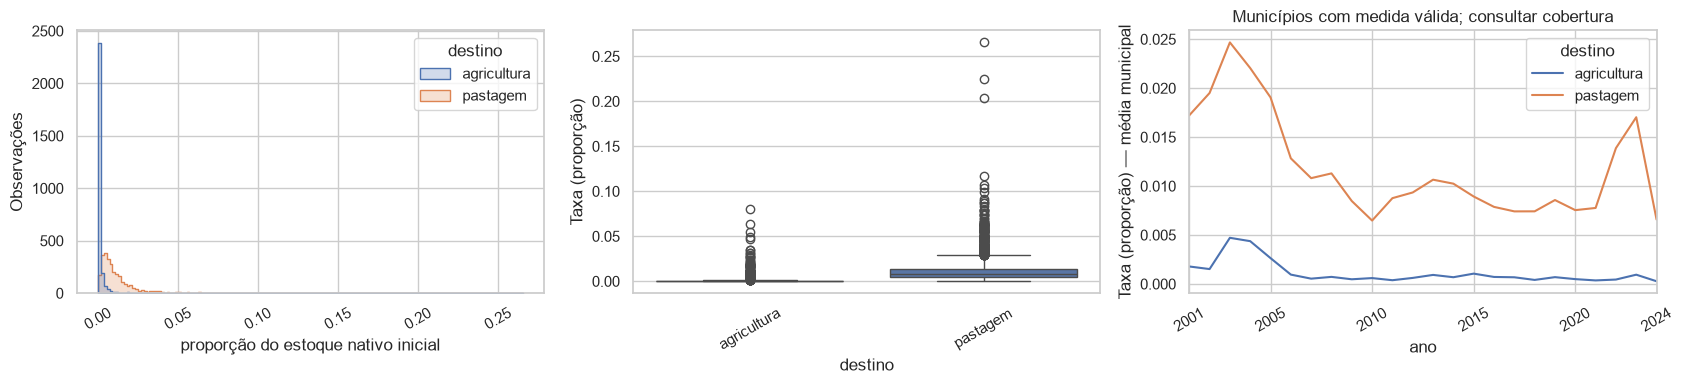

In [12]:
# Usamos o Y efetivamente construído, mantendo os destinos separados.
if "taxas" in tabelas_derivadas:
    y = tabelas_derivadas["taxas"].copy()
    MEDIDA_Y = "taxa_conversao"
    cobertura_y = y.groupby(["ano", "destino"], observed=True).agg(
        municipios=("codigo_ibge", "nunique"),
        medidas_validas=(MEDIDA_Y, "count"),
        media_municipal=(MEDIDA_Y, "mean"),
    ).reset_index()
    display(cobertura_y)
    display(y.groupby("destino", observed=True)[MEDIDA_Y].describe())
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    sns.histplot(data=y, x=MEDIDA_Y, hue="destino", element="step", ax=axes[0])
    sns.boxplot(data=y, x="destino", y=MEDIDA_Y, ax=axes[1])
    sns.lineplot(data=cobertura_y, x="ano", y="media_municipal", hue="destino", ax=axes[2])
    axes[0].set_xlabel("proporção do estoque nativo inicial")
    axes[0].set_ylabel("Observações")
    axes[1].set_ylabel("Taxa (proporção)")
    axes[2].set_ylabel("Taxa (proporção) — média municipal")
    axes[2].set_title("Municípios com medida válida; consultar cobertura")
    axes[2].set_xlim(2001, 2024)
    axes[2].set_xticks([2001, 2005, 2010, 2015, 2020, 2024])
    for ax in axes:
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("Os gráficos de Y aguardam a aquisição completa das transições.")
